In [1]:
from pathlib import Path
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# 1. Specify the MATLAB file location.
file_path = Path(
    r"C:\Users\redhu\OneDrive\Desktop\Bearing_fault_detection"
    r"\data\raw\paderborn\K001\K001\N15_M07_F10_K001_1.mat"
)


In [3]:
# 2. Load the file and open its recording structure.
recording = loadmat(file_path)[file_path.stem][0, 0]

In [4]:
# 3. Find the vibration channel by name.
channels = recording["Y"].ravel()
names = [channel["Name"].item() for channel in channels]
names

['force',
 'phase_current_1',
 'phase_current_2',
 'speed',
 'temp_2_bearing_module',
 'torque',
 'vibration_1']

In [9]:
vibration=channels[names.index('vibration_1')]

In [10]:
vibration.dtype.names

('Name',
 'Type',
 'Data',
 'Unit',
 'Raster',
 'Device',
 'XIndex',
 'DownSampling',
 'Description',
 'DisplayIdentifier',
 'Path',
 'Flags',
 'Min',
 'Max',
 'MinWeak',
 'MaxWeak')

In [11]:
# 4. Extract the vibration values.
x = vibration["Data"].ravel().astype(float)

In [12]:
# 5. Extract the matching stored time values using XIndex.
axis_index = int(vibration["XIndex"].item()) - 1
t_stored = recording["X"].ravel()[axis_index]["Data"].ravel()

In [25]:
# 6. Set the documented nominal sampling rate.
fs = 64_000

print("Vibration samples:", x.size)
print("Time values:", t_stored.size)
print("First five vibration values:", x[:5])
print("First five time values:", t_stored[:5])
print("Stored time span (seconds):", t_stored[-1] - t_stored[0])

Vibration samples: 256001
Time values: 256001
First five vibration values: [-0.04882812  0.2166748   0.23498535  0.390625    0.00305176]
First five time values: [0.00000000e+00 1.58257762e-05 3.12238287e-05 4.70496048e-05
 6.24476573e-05]
Stored time span (seconds): 3.999998716828959


In [26]:
print("Matching lengths:", x.size == t_stored.size)
print("All vibration values finite:", np.isfinite(x).all())
print("All time values finite:", np.isfinite(t_stored).all())
print("Time always increases:", (np.diff(t_stored) > 0).all())

Matching lengths: True
All vibration values finite: True
All time values finite: True
Time always increases: True


In [27]:
# Time between the first and last sample.
time_span = t_stored[-1] - t_stored[0]

# Estimate the average sampling rate across that span.
fs_check = (x.size - 1) / time_span

print(f"Stored time span: {time_span:.6f} seconds")
print(f"Sampling rate from time span: {fs_check:.4f} Hz")
print(f"Documented nominal sampling rate: {fs} Hz")

Stored time span: 3.999999 seconds
Sampling rate from time span: 64000.0205 Hz
Documented nominal sampling rate: 64000 Hz


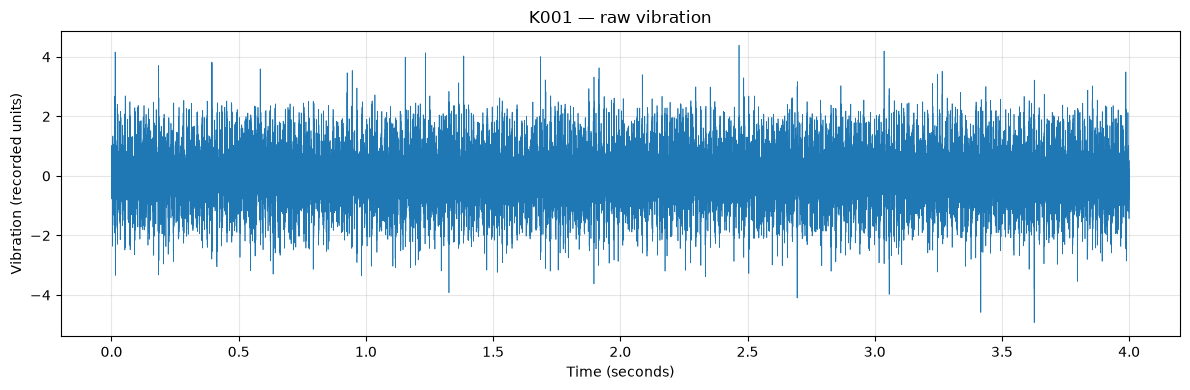

In [28]:
# Create time coordinates using the nominal sampling rate.
t = np.arange(x.size) / fs

plt.figure(figsize=(12, 4))
plt.plot(t, x, linewidth=0.5)
plt.xlabel("Time (seconds)")
plt.ylabel("Vibration (recorded units)")
plt.title("K001 — raw vibration")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

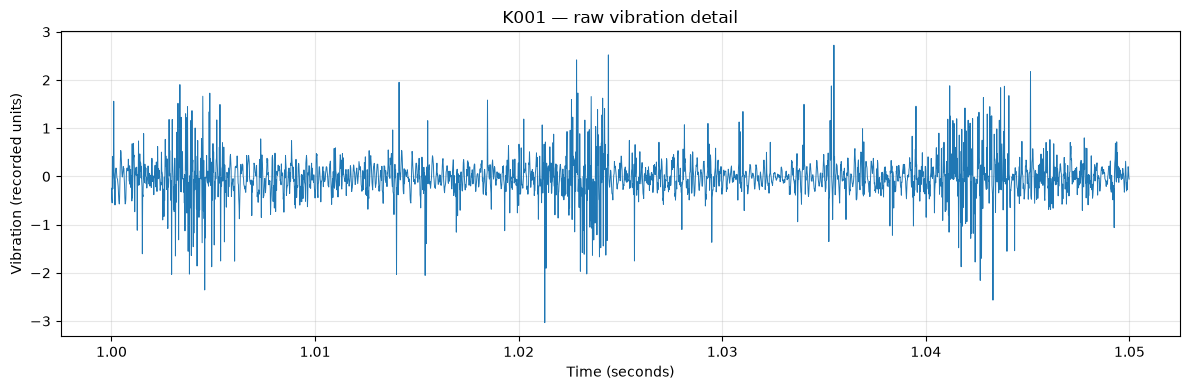

In [29]:
# Select samples between 1.00 and 1.05 seconds.
mask = (t >= 1.00) & (t < 1.05)

plt.figure(figsize=(12, 4))
plt.plot(t[mask], x[mask], linewidth=0.7)
plt.xlabel("Time (seconds)")
plt.ylabel("Vibration (recorded units)")
plt.title("K001 — raw vibration detail")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()